# EOS Consistency Check

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [3]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')

In [4]:
import dispatch
import dispatch.EOS
from dispatch.EOS import deriv,interp

## Get JCD model S data

In [5]:
from dispatch.solar_models import JCD_S
model=JCD_S(top=top)

Get ``(log(rho),log(E))``

In [6]:
def model_S(eos):
    """ Return (log10(rho), log10(E)), where rho[i] is from JCD model S, and
        E is from the EOS enegy E[i] that corresponds to T[i] from the model.
    """
    s0=eos.scale0
    vars=eos.variables.values()
    ln10=np.log(10.0)
    LogE=[]
    LogD=[]
    for i,rho in enumerate(model.rho):
        lnd=np.log(rho)
        if eos.type=='stagger-E':
            lnd=lnd+np.log(1e7)
        if lnd < s0.max:
            ir,p=s0.index(lnd)
            if ir<s0.n:
                if eos.type=='stagger-E':
                    E,T=eos.values(ir,'T')
                    lnE=np.log(E)
                elif eos.type=='bifrost':
                    lnE,T=eos.values(ir,'T')
                elif eos.type=='tomida':
                    lnT,lnE=eos.values(ir,'ln(E)')
                    T=np.exp(lnT)
                j=np.where(T > model.T[i])[0]
                if len(j)>1:
                    j=j[0]
                    log_d=np.log10(rho)
                    log_E=lnE[j]/ln10
                    E=10.**log_E
                    fmt='{:4d}  {:10.0f} {:10.1f}  {:10.1f} {:10.0f}'
                    #print(fmt.format(j,model.T[i],lnd,E,eos.lookup('T',lnd,E)))
                    #print(i,log_d,log_E)
                    LogE.append(log_E)
                    LogD.append(log_d)
    return np.array(LogD),np.array(LogE)

12727.035


12875.025091584568

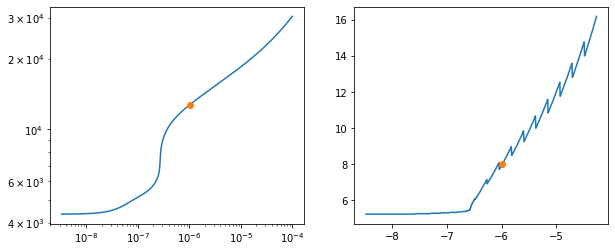

In [7]:
model=dispatch.solar_models.JCD_S(top=top)

pl.figure(figsize=(10,4))
pl.subplot(1,2,1)
w=np.where(model.rho<1e-4)[0]
pl.loglog(model.rho[w],model.T[w]);
w=np.where(model.rho>1e-6)[0][0]
pl.loglog(model.rho[w],model.T[w],'o')
print(model.T[w])

eos=dispatch.EOS.open(top=top)
logD,logE=model_S(eos)
pl.subplot(1,2,2)
w=np.where(10**logD<1e-4)[0]
pl.plot(logD[w],10.**logE[w]);
E0=8
pl.plot(-6,E0,'o')
eos.lookup('T',np.log(10),E0)

## Stagger model EOS

In [8]:
def plot_incons(eos,c):
    print(eos.type)
    T=eos.scale1.values
    lnd=eos.scale0.values
    pl.figure(figsize=(12,4))
    for i in (0,1):
        pl.subplot(1,2,1+i)
        ln10=np.log(10)
        if eos.type=='stagger-E':
            e=(eos.scale0.min/ln10-7,eos.scale0.max/ln10-7,eos.scale1.min*1e12,eos.scale1.max*1e12)
        else:
            e=(eos.scale0.min/ln10-7,eos.scale0.max/ln10,eos.scale1.min,eos.scale1.max)
        if i:
            cl=np.log10(np.abs(c)+1e-10)
            pl.imshow(cl.T,vmin=-5,vmax=-1.3,extent=e,aspect='auto',origin='lower')
        else:
            vmax=0.03
            pl.imshow(c.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
        pl.xlabel('log10(rho)'); pl.ylabel('E'); pl.title(eos.file+'  log10(abs(error)')
        pl.colorbar();
        logD,logE=model_S(eos)
        #print(logD.min(),logD.max(),10**logE.min(),10**logE.max())
        if eos.type=='stagger-E':
            pl.plot(logD,10**(logE)*1e12,color='k')
            pl.plot(-12,21e12,'s',color='b')
        elif eos.type=='tomida':
            pl.plot(logD,10**(logE)*1e12,color='k')
            pl.plot(-12,21e12,'s',color='b')            
        pl.xlim(-10,0); pl.ylim(3e12,80e12);    
    pl.tight_layout()

stagger-E


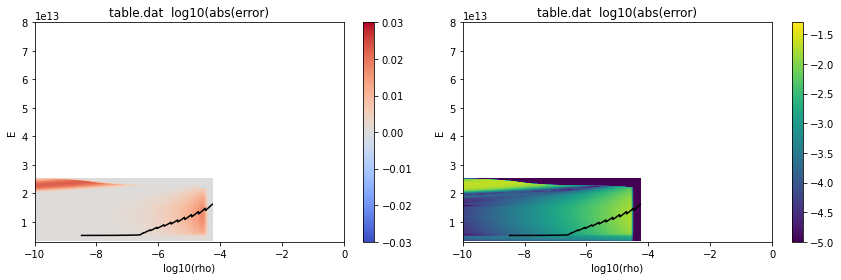

In [9]:
eos=dispatch.EOS.open('stagger','table.dat',top=top)
c=dispatch.EOS.consistencies(eos)
eos.scale1.name
plot_incons(eos,c)


stagger-E


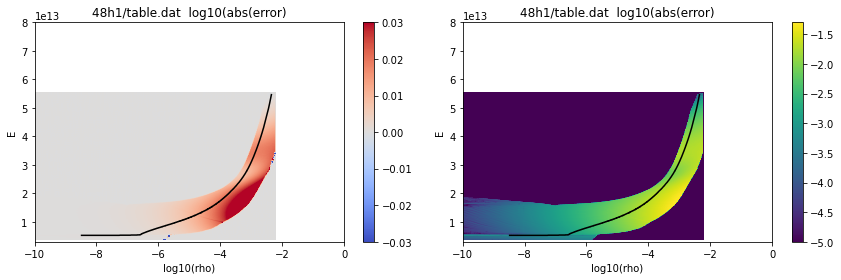

In [10]:
eos=dispatch.EOS.open('stagger','48h1/table.dat',top=top)
c=dispatch.EOS.consistencies(eos)
eos.scale1.name
plot_incons(eos,c)

## Tomida & Hori (2016) EOS

In [11]:
eos=dispatch.EOS.open('tomida',top=top)

In [12]:
c=np.zeros((eos.scale0.n,eos.scale1.n))
for i in range(1,eos.scale0.n-1):
    c[i,:]=dispatch.EOS.consistency(eos,i)

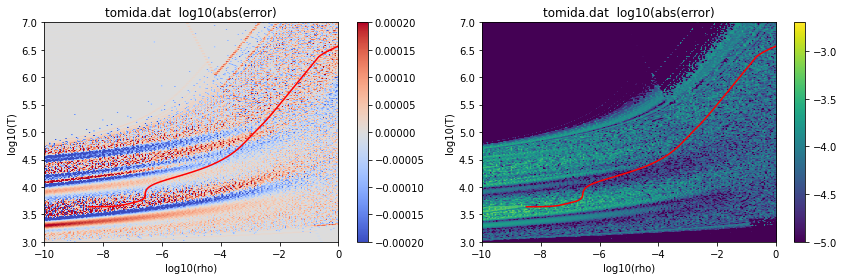

In [13]:
pl.figure(figsize=(12,4))
for i in (0,1):
    pl.subplot(1,2,1+i)
    T=eos.scale1.values
    lnd=eos.scale0.values
    ln10=np.log(10)
    vmax=0.02
    e=(eos.scale0.min/ln10,eos.scale0.max/ln10,eos.scale1.min/ln10,eos.scale1.max/ln10)
    if i:
        cl=np.log10(np.abs(c)+1e-10)
        pl.imshow(cl.T,vmin=-5,vmax=-2.7,extent=e,aspect='auto',origin='lower')
    else:
        vmax=2e-4
        pl.imshow(c.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,aspect='auto',origin='lower')
    w=np.where(model.rho<10.)[0]
    pl.xlabel('log10(rho)'); pl.ylabel('log10(T)'); pl.title(eos.file+'  log10(abs(error)')
    pl.colorbar()
    pl.plot(np.log10(model.rho[w]),np.log10(model.T[w]),color='r')
    pl.xlim(-10,0); pl.ylim(3,7);
pl.tight_layout()

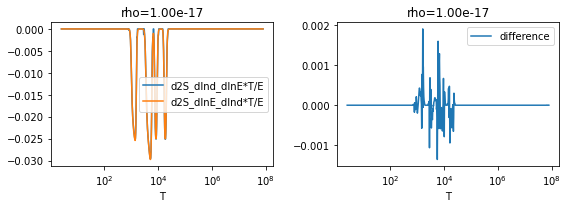

In [14]:
dispatch.EOS.consistency(eos,100,plot=1);

## Bifrost EOS

In [15]:
eos=dispatch.EOS.open('bifrost',top=top)
eos.scale1.name,eos.file

('ln(E)', 'eostable.dat')

In [16]:
c=np.zeros((eos.scale0.n,eos.scale1.n))
for i in range(1,eos.scale0.n-1):
    c[i]=dispatch.EOS.consistency(eos,i)

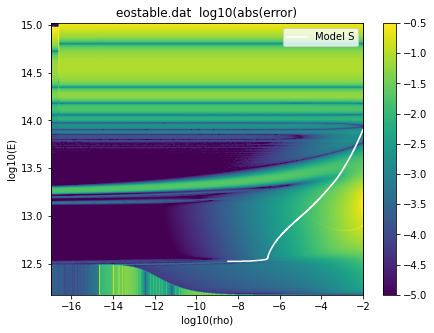

In [17]:
lnE=eos.scale1.values
lnd=eos.scale0.values
pl.figure(figsize=(7,5))
ln10=np.log(10)
e=(eos.scale0.min/ln10,eos.scale0.max/ln10,
   eos.scale1.min/ln10,eos.scale1.max/ln10)
if 1:
    cl=np.log10(np.abs(c)+1e-10)
    pl.imshow(cl.T,vmin=-5,vmax=-0.5,extent=e,aspect='auto',origin='lower')
else:
    vmax=3e-4
    pl.imshow(c.T,vmin=-vmax,vmax=vmax,cmap='coolwarm',extent=e,
              aspect='auto',origin='lower')
pl.xlabel('log10(rho)'); pl.ylabel('log10(E)')
pl.title(eos.file+'  log10(abs(error)')
pl.colorbar();
logD,logE=model_S(eos)
pl.plot(logD,logE,color='w',label='Model S');
#pl.xlim(-10,0); #pl.ylim(3,7);
pl.legend();